# Notebook 03 — Preparing the data for training

In notebook 02 the scripted driver recorded about 296 drives into six folders (`runs/datasets/expert_sgc_*`). A neural
network can't learn from folders of videos directly. It needs a stream of **training samples**, each one an input and
the correct answer, delivered quickly, in random order, and in the exact format the model expects.

This notebook builds that stream. Every step exists to prevent a specific, well-known failure, and
for each one we explain the failure first.

**What you will learn here**
1. Why the train/validation split must be made **by layout** (whole rooms), and what "data leakage" is.
2. **Action chunks**: why modern robot policies predict the next second of actions, not just the next one.
3. **Normalisation**: why the scale of the numbers matters, and why we scale by the car's speed limits.
4. **Data augmentation**: making extra, *correct* training data by mirroring images and paraphrasing prompts,
   and why we mirror only when the data allows it.
5. How a PyTorch `Dataset` and `DataLoader` deliver batches, and how to check their speed.

**The settings, decided in this notebook**

| Setting | Value | Section |
|---|---|---|
| Training data | the scripted drives only | 3 |
| Validation | 10% of the room layouts, never trained on | 4 |
| Held-out goal | "orange sphere" is never a training goal | 4 |
| Chunk length | 10 steps (1 s) | 5 |
| Scaling | divide by the car's speed limits | 6 |
| Mirroring | **off** for this data | 7 |
| Prompt paraphrases | on | 8 |

## 1. Setup

In [1]:
import sys, json, time, glob
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
RUNS = PROJECT_ROOT / "runs"
CACHE = RUNS / "cache"; CACHE.mkdir(parents=True, exist_ok=True)
PREP = RUNS / "datasets" / "scripted_close_prep.json"     # the file this notebook writes; notebooks 04 and 05 read it

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from carsim.config import CarConfig
from carsim.data import (ActionScaler, Paraphraser, NavChunkDataset, make_scripted_prep, load_training_data,
                         MIRROR_SIGN, TRAIN_VERBS, EVAL_VERBS, SHAPE_SYNONYMS)
car_cfg = CarConfig()

# Settings for this notebook (the table above)
FRAC_VAL = 0.10
CHUNK = 10
MIRROR_P = 0.0     # mirroring off for the scripted data (section 7); 0.5 would mirror half the samples

## 2. The pipeline at a glance

```
 6 LeRobot datasets (video + parquet), notebook 02
        │  stack them into ONE table, decode every frame ONCE      (section 3)
        ▼
 frame cache: one big uint8 array, about 3.8 GB, read from disk on demand
        │
        │  split by LAYOUT → ~265 train / ~27 val drives            (section 4)
        ▼
 NavChunkDataset[i]  ──►  image  +  speed  +  prompt   →  inputs
                          next 10 actions (a "chunk")  →  what the model must predict   (section 5)
                          goal bearing / distance      →  extra targets for the quiz in notebook 04
        │  scale actions to [-1, 1]                                 (section 6)
        │  training only: random prompt paraphrase (mirroring: off)  (sections 7, 8)
        ▼
 DataLoader: shuffles, groups into batches of e.g. 32, uses 4 CPU workers   (section 9)
```
The code lives in `carsim/data.py`; this notebook explains and checks every piece.

## 3. Combine the recordings and decode them once

`make_scripted_prep` (in `carsim/data.py`) does the whole preparation in one call, and the rest of this notebook
opens it up and checks every piece:

1. **One table.** The six recordings are stacked into one table. Frame and episode numbers are shifted so every
   number stays unique (folder 2 starts where folder 1 ends).
2. **One frame cache.** Video files are compressed *relative to neighbouring frames*. To get frame 1234 the decoder
   must first find the nearest key frame and decode from there. That's fine for watching a video from start to end,
   but training reads frames in **random order**, hundreds of thousands of times. So we pay the decoding cost once:
   about 19,000 frames × 196 KB ≈ 3.8 GB, saved as a `.npy` file and opened as a *memory map*: the operating system
   loads pages from disk on demand and keeps them in RAM while there is room.
3. **The split** (section 4) and the settings, written to a small JSON file (section 10).

`load_training_data` reads it all back: the settings (`prep`), the frame table, the frames, and one row per episode
(rebuilt from each layout's seed, so we know the goal object and whether it was visible at the start).

The first run takes about **2 minutes** (decoding); afterwards it is instant.

In [2]:
folders = sorted(glob.glob(str(RUNS / "datasets" / "expert_sgc_*[0-9]")))
assert len(folders) == 6, "Record the scripted drives first: notebook 02, section 10"
t0 = time.time()
make_scripted_prep(folders, PREP, source="expert_close", frac_val=FRAC_VAL)
prep, table, frames, episodes = load_training_data(PREP)
split = prep["split"]
print(f"frame cache {frames.shape} {frames.dtype}, {frames.nbytes / 1e9:.2f} GB, ready in {time.time() - t0:.0f} s")
print(f"{len(episodes)} drives, {len(table)} frames ({len(table) / 10 / 60:.0f} minutes of driving)")
episodes.head()

/home/mayur/Projects/obstacle_avoidance/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


expert_close           drives  296  frames  19296  train drives 265


frame cache (19296, 256, 256, 3) uint8, 3.79 GB, ready in 12 s
296 drives, 19296 frames (32 minutes of driving)


,episode_index,start,stop,n_frames,seed,goal,colour,shape,prompt,start_visible,collision_steps
0,0,0,120,120,666291128,yellow sphere,yellow,sphere,move to the yellow ball,False,0
1,1,120,192,72,2026220626,red cube,red,cube,head to the red block,False,0
2,2,192,260,68,1495899628,yellow cube,yellow,cube,drive to the yellow cube,False,0
3,3,260,333,73,771850791,yellow cube,yellow,cube,move to the yellow block,True,0
4,4,333,404,71,289607014,red sphere,red,sphere,go to the red ball,False,0


## 4. Train/validation split, by episode

During training we watch two losses:
- **training loss**, on the samples the model learns from;
- **validation loss**, on samples it **never** learns from.

If the training loss falls but the validation loss rises, the model is **overfitting**: it memorises
its training examples instead of learning the skill. To detect that, the validation samples must be
genuinely *new* to the model.

**The trap: splitting by frame.** Our frames come at 10 per second, so neighbouring frames are almost
identical. If frame 100 is in training and frame 101 in validation, the model has effectively seen
the validation answer. The validation loss then looks great and means nothing. This is called
**data leakage**. The plot below shows how similar neighbouring frames really are.

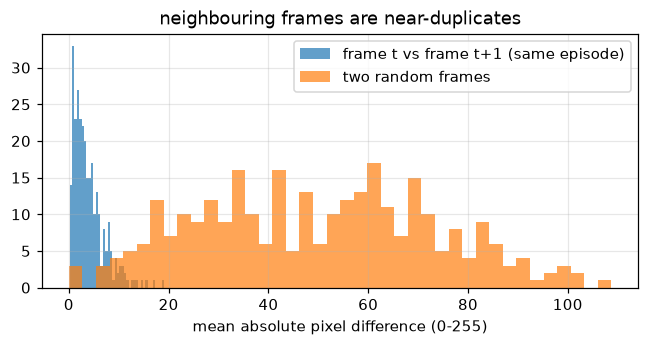

In [3]:
rng = np.random.default_rng(0)
idx = rng.integers(0, len(frames) - 1, 300)
same_ep = table.episode_index.to_numpy()
idx = idx[same_ep[idx] == same_ep[idx + 1]]
neighbour = [np.abs(frames[i].astype(int) - frames[i + 1]).mean() for i in idx]
random_pair = [np.abs(frames[i].astype(int) - frames[j]).mean() for i, j in zip(idx, rng.permutation(idx))]
plt.figure(figsize=(7, 3))
plt.hist(neighbour, bins=40, alpha=0.7, label="frame t vs frame t+1 (same episode)")
plt.hist(random_pair, bins=40, alpha=0.7, label="two random frames")
plt.xlabel("mean absolute pixel difference (0-255)"); plt.legend(); plt.title("neighbouring frames are near-duplicates")
plt.show()

So we split **whole layouts**: about 10% of the rooms go to validation, and the model never trains on them. Why
layouts and not drives? In the "words" scenes the same room is often driven twice, asking for a different object
each time. Both drives start from the *same picture*. If one were in training and the other in validation,
validation would show the model a picture it has already learned from, and look better than it really is. So both
always go to the same side (`split_by_layout` in `carsim/data.py`).

**The held-out goal.** Drives whose goal is the "orange sphere" are left out of both sides. The model sees orange
cubes and cylinders, and spheres in other colours, but never drives to an orange sphere. That keeps a possible later
test: does it *combine* "orange" and "sphere", two words it learned separately (*compositional generalisation*)?

A word of honesty about validation loss in robotics: it is a useful *alarm* (for overfitting or bugs),
but a low loss doesn't guarantee good driving. A tiny error in each step can still add up over a whole
drive (compounding errors, notebook 02). The real test is to let the model drive in the simulator,
which notebooks 04 and 05 do.

{'train': '265 drives', 'val': '27 drives', 'excluded': '4 drives'}
excluded drives (goal held out): ['orange sphere']


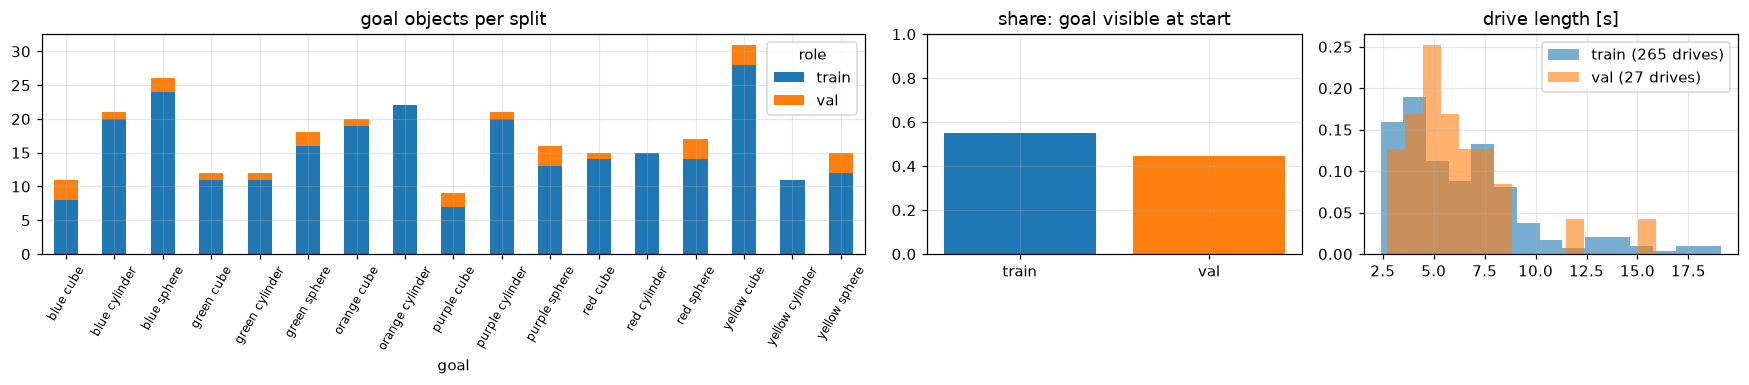

In [4]:
print({k: (f"{len(v)} drives" if k in ("train", "val", "excluded") else v) for k, v in split.items() if k != "held_out_goals"})
ep = episodes.set_index("episode_index")
role = pd.Series("excluded", index=ep.index); role[split["train"]] = "train"; role[split["val"]] = "val"
ep["role"] = role
print("excluded drives (goal held out):", sorted(ep[ep.role == "excluded"].goal.unique()))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [2.2, 1, 1]})
goal_counts = ep[ep.role != "excluded"].groupby(["goal", "role"]).size().unstack(fill_value=0)
goal_counts.plot.bar(stacked=True, ax=axes[0], color={"train": "tab:blue", "val": "tab:orange"})
axes[0].set_title("goal objects per split"); axes[0].tick_params(axis="x", rotation=60, labelsize=8)
for r, g in ep[ep.role != "excluded"].groupby("role"):
    axes[1].bar(r, g.start_visible.mean(), color="tab:blue" if r == "train" else "tab:orange")
axes[1].set_ylim(0, 1); axes[1].set_title("share: goal visible at start")
for r, g in ep[ep.role != "excluded"].groupby("role"):
    axes[2].hist(g.n_frames / 10, bins=15, alpha=0.6, density=True, label=f"{r} ({len(g)} drives)")
axes[2].set_title("drive length [s]"); axes[2].legend()
plt.tight_layout(); plt.show()

**How to read it.** Left: every goal object should appear in training (blue); validation (orange) is a small sample
of the same mix. Middle: both sides should have a similar share of drives where the goal is visible at the start,
otherwise one side is easier than the other. Right: the drive lengths should look alike. With a random 10% split
the validation side is small (about 27 drives), so its bars are bumpier; that's expected.

## 5. Action chunks: predicting the next second

The simplest policy predicts **one** action from the current image. Modern robot policies (ACT,
π0, smolVLA) instead predict a **chunk**: the next *H* actions at once. Here H = 10, which is 1 s.

**Why chunks help**
- **Consistency.** Remember multimodality: left *or* right around an obstacle. A single-step policy
  can pick "left" now and "right" 0.1 s later, wobbling into the obstacle. A chunk commits to one
  coherent plan for the next second.
- **Smoother targets.** One action is noisy (with human drivers: finger timing). A sequence of 10 shows the *intent*,
  which is easier to relate to the image.
- **Speed.** A big model doesn't need to run at every control step. It can predict a chunk, execute
  part of it, then predict again.

**Why not long chunks?** smolVLA's default is 50 steps, i.e. 5 s at our 10 Hz. That's fine for a slow
arm task, but a car driving at 0.8 m/s moves 4 m in 5 s, and the view changes completely. The plot
below shows how quickly the recorded actions change. The correlation between the action now and the action
*k* steps later tells us over what horizon the future is still predictable.

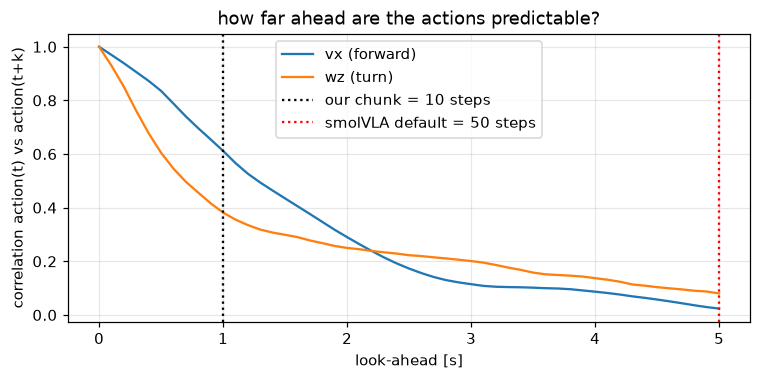

In [5]:
A = table[["action.vx", "action.vy", "action.wz"]].to_numpy()
E = table.episode_index.to_numpy()
lags = np.arange(0, 51)
plt.figure(figsize=(8, 3.4))
for j, name in [(0, "vx (forward)"), (2, "wz (turn)")]:
    corr = []
    for k in lags:
        ok = (E[: len(E) - k] == E[k:])
        a, b = A[: len(A) - k, j][ok], A[k:, j][ok]
        corr.append(np.corrcoef(a, b)[0, 1])
    plt.plot(lags / 10, corr, label=name)
plt.axvline(CHUNK / 10, color="k", ls=":", label=f"our chunk = {CHUNK} steps")
plt.axvline(5.0, color="r", ls=":", label="smolVLA default = 50 steps")
plt.xlabel("look-ahead [s]"); plt.ylabel("correlation action(t) vs action(t+k)")
plt.title("how far ahead are the actions predictable?"); plt.legend(); plt.show()

How to read this: for the forward speed (vx) the correlation is still about 0.6 at 1 s but only about 0.1 at 3 s;
for turning (wz) it drops faster, to about 0.4 at 1 s, and is near 0.1 by 5 s. In plain words: what the car does
3–5 s from now has little to do with what it is doing now, because by then it has driven past things and is reacting
to a different view. A 50-step chunk would ask the model to guess those unguessable seconds.

A 10-step chunk reaches into the partly predictable window. Two more points:
- The model doesn't have to execute all 10 actions blindly. A common pattern is to execute only the
  first few, then predict a fresh chunk from the new image. We use 5 of 10 (0.5 s) in
  notebooks 04 and 05.
- With human drivers, part of the drop is plain unpredictability in *timing* (exactly when a key was released).
  No model can predict that from an image, which is another reason not to make chunks long.

**What happens at the end of an episode?** For the last frames there are fewer than 10 future
actions left. After success the car stands still at the goal, so the natural continuation is
"action = 0", and that's what we fill in. We also return a mask, `action_pad`, so that notebook 04 can
choose to include or ignore those filled-in steps in the loss.

Below: one episode's turn command, with the chunk the model must predict from three moments in it.

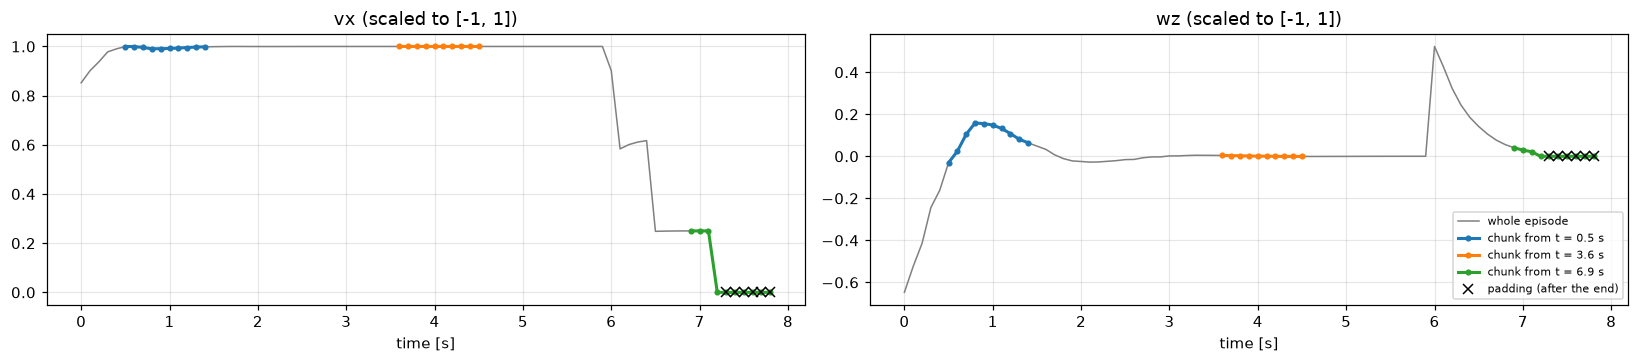

In [6]:
scaler = ActionScaler.from_car(car_cfg)
demo = NavChunkDataset(table, frames, episodes, split["train"], scaler, chunk=CHUNK)
e0 = split["train"][3]
rows = np.flatnonzero(demo.ep_of == e0)
g = table[table.episode_index == e0]
fig, axes = plt.subplots(1, 2, figsize=(15, 3.4))
for ax, (j, name) in zip(axes, [(0, "vx"), (2, "wz")]):
    ax.plot(g.frame_index / 10, g[f"action.{['vx', 'vy', 'wz'][j]}"] / scaler.limits[j], color="grey", lw=1, label="whole episode")
    for k, r in enumerate([rows[5], rows[len(rows) // 2], rows[-4]]):
        s = demo[r]
        t0 = (s["frame"] - g["index"].min()) / 10
        tt = t0 + np.arange(CHUNK) / 10
        ax.plot(tt, s["action"][:, j], "o-", ms=3, lw=2, label=f"chunk from t = {t0:.1f} s")
        pad = s["action_pad"].numpy()
        if pad.any():
            ax.plot(tt[pad], s["action"].numpy()[pad, j], "kx", ms=7, label="padding (after the end)")
    ax.set_title(f"{name} (scaled to [-1, 1])"); ax.set_xlabel("time [s]")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 6. Scaling the numbers

Neural networks learn best when their inputs and outputs are numbers of roughly size 1. A flow-matching
head in particular starts every prediction from **random noise with standard deviation 1** and
gradually turns it into an action. If the target actions lived on a very different scale, the noise
would either drown them or barely touch them.

There are two common ways to scale:
- **mean/std normalisation** (smolVLA's default): `(a - mean) / std`;
- **range scaling**: divide by known limits, so that every value lies in [-1, 1].

We use **range scaling by the car's speed limits** (0.8 m/s, 0.6 m/s, 1.5 rad/s). The histograms show why:

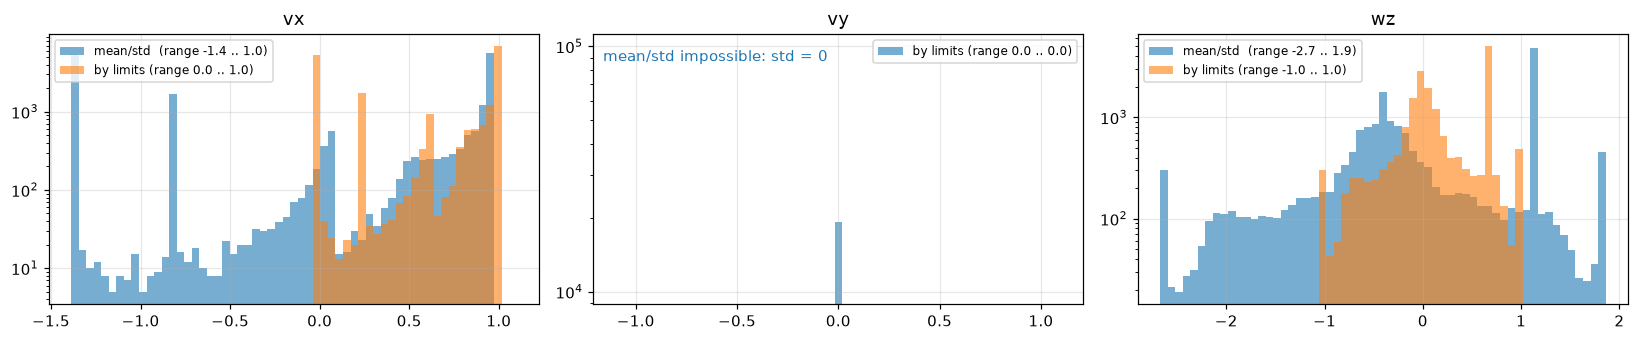

std of vy in this data: 0.000 m/s (the scripted driver never strafes)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, j, name in zip(axes, range(3), ["vx", "vy", "wz"]):
    a = A[:, j]
    r = a / scaler.limits[j]
    if a.std() > 0:
        z = (a - a.mean()) / a.std()
        bins = np.linspace(min(z.min(), -1.1), max(z.max(), 1.1), 60)
        ax.hist(z, bins=bins, alpha=0.6, label=f"mean/std  (range {z.min():.1f} .. {z.max():.1f})")
    else:
        bins = np.linspace(-1.1, 1.1, 60)
        ax.text(0.02, 0.9, "mean/std impossible: std = 0", transform=ax.transAxes, color="tab:blue")
    ax.hist(r, bins=bins, alpha=0.6, label=f"by limits (range {r.min():.1f} .. {r.max():.1f})")
    ax.set_yscale("log"); ax.set_title(name); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"std of vy in this data: {A[:, 1].std():.3f} m/s (the scripted driver never strafes)")

- **vy (strafing)**: the scripted driver never strafes, so vy is always 0 and its standard deviation is 0:
  mean/std scaling would divide by zero. Even with human drives, where strafing happens in a few per cent of frames,
  the standard deviation is tiny and the rare strafes become huge numbers (about 8 in the author's drives), far
  outside the noise's scale. With range scaling every value stays within ±1.
- Range scaling keeps **0 at 0** (standing still is exactly zero) and is **symmetric**, so a mirrored
  action (section 7) is still correctly scaled. With mean/std, a non-zero mean would break that.
- The measured speed (the `state` input) is scaled the same way.

The model's outputs are converted back with `scaler.unscale(...)` before being sent to the car.

## 7. Mirror augmentation: free, *correct* extra data

**Data augmentation** means creating extra training samples by transforming existing ones, for example
by flipping or recolouring them. The transformed sample must still have a **correct label**.

Flipping the camera image left↔right is a perfect fit for our task. A mirrored world is still a valid
world, but everything sideways swaps:

| quantity | after mirroring | why |
|---|---|---|
| image | flipped horizontally | the world as seen in a mirror |
| vx (forward) | unchanged | forward is still forward |
| vy (strafe, + = left) | **negated** | left becomes right |
| wz (turn, + = counter-clockwise) | **negated** | a left turn becomes a right turn |
| goal bearing (+ = goal on the left) | **negated** | the goal moves to the other side |

**When it helps:** with human drives, mirroring guarantees that every situation appears in both its left and its
right version, with consistent labels, so the model can't pick up a lopsided habit like "usually turn right".

**Check it with your own eyes.** The images below show an original sample and its mirror. Yellow
dashed line = where the goal *should* be, computed from the stored (and, for the mirror, negated)
bearing. If our sign rules are right, the line passes through the goal in **both** images. Arrows:
the commanded motion (forward/sideways) and the turn direction.

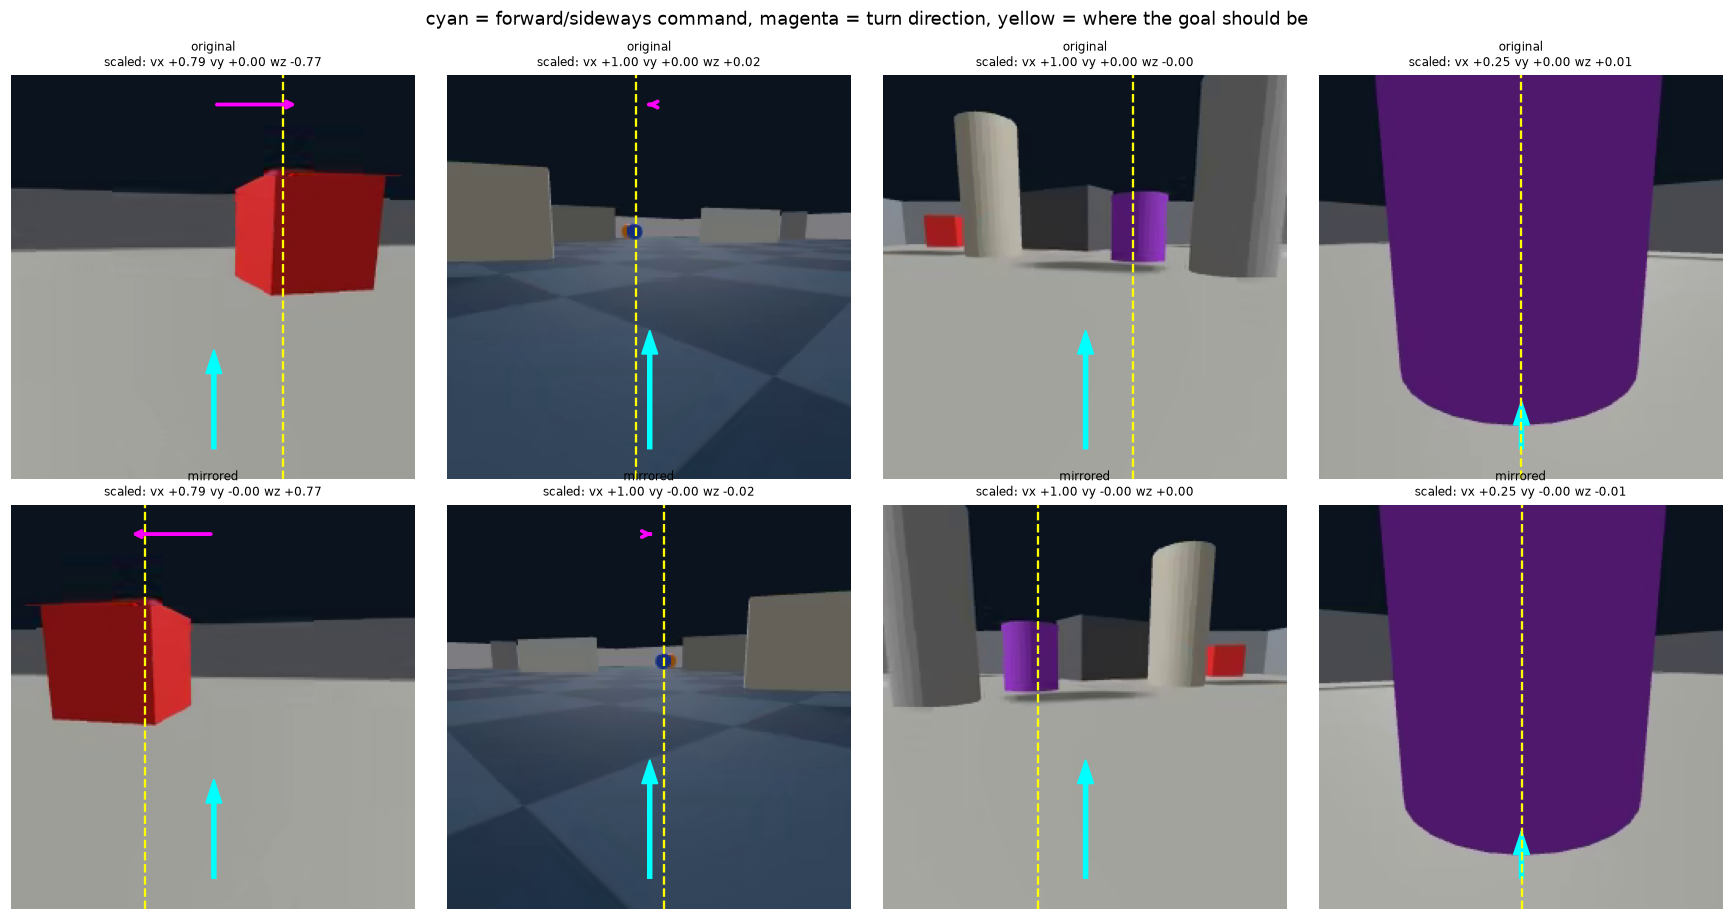

In [8]:
FOV = np.radians(car_cfg.cam_fov_deg)

def show_sample(ax, s, title=""):
    img = s["image"].permute(1, 2, 0).numpy(); H, W = img.shape[:2]
    ax.imshow(img); ax.axis("off")
    bearing = np.arctan2(float(s["aux"][0]), float(s["aux"][1]))
    if abs(bearing) < FOV / 2:
        x = W / 2 - np.tan(bearing) / np.tan(FOV / 2) * W / 2
        ax.axvline(x, color="yellow", ls="--", lw=1.5)
    a = s["action"][0].numpy()
    if np.hypot(a[0], a[1]) > 0.02:  # (a zero-length arrow would draw a stray arrow head)
        ax.arrow(W / 2, H - 20, -a[1] * 60, -a[0] * 60, color="cyan", width=2.5, head_width=10)
    if abs(a[2]) > 0.02:
        ax.annotate("", xy=(W / 2 - a[2] * 70, 18), xytext=(W / 2, 18),
                arrowprops=dict(arrowstyle="->", color="magenta", lw=2.5))
    ax.set_title(title, fontsize=8)

train_ds = NavChunkDataset(table, frames, episodes, split["train"], scaler, chunk=CHUNK, mirror_p=MIRROR_P, paraphrase=True)
# (for the pictures below we switch mirroring fully off / fully on, then restore MIRROR_P)
vis = np.flatnonzero(train_ds.aux[train_ds.index, 3] > 0)  # frames where the goal is visible
picks = np.random.default_rng(3).choice(vis, 4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for k, i in enumerate(picks):
    train_ds.mirror_p = 0.0; o = train_ds[i]
    train_ds.mirror_p = 1.0; m = train_ds[i]
    fmt = lambda s: "scaled: " + f"vx {s['action'][0,0]:+.2f} vy {s['action'][0,1]:+.2f} wz {s['action'][0,2]:+.2f}"
    show_sample(axes[0, k], o, "original\n" + fmt(o))
    show_sample(axes[1, k], m, "mirrored\n" + fmt(m))
train_ds.mirror_p = MIRROR_P
fig.suptitle("cyan = forward/sideways command, magenta = turn direction, yellow = where the goal should be", y=0.99)
plt.tight_layout(); plt.show()

A **numbers check** to go with the visual one: when the goal is on the left (positive bearing), a good
driver turns left (positive wz). So bearing and wz should be *positively* correlated, in the original
data *and* in the mirrored data. A sign error would make the mirrored correlation negative.

In [9]:
idx = train_ds.index
b = train_ds.aux[idx, 0]; w = train_ds.actions[idx, 2]
moving = np.abs(w) > 0.01
print(f"corr(sin bearing, wz) original: {np.corrcoef(b[moving], w[moving])[0, 1]:+.2f}   "
      f"mirrored: {np.corrcoef(-b[moving], -w[moving])[0, 1]:+.2f}")
print(f"left turns vs right turns in the scripted data: {(w > 0.01).mean():.1%} vs {(w < -0.01).mean():.1%}")

corr(sin bearing, wz) original: +0.40   mirrored: +0.40
left turns vs right turns in the scripted data: 60.0% vs 32.9%


The correlation is the same, positive number in both: good. (It comes out *exactly* the same
because negating both quantities leaves a correlation unchanged; the real test of the signs is the
yellow line in the images above.)

**So why is mirroring off here?** The scripted driver searches for a hidden goal by **always turning left** (notebook
02). That is a perfectly learnable habit. With mirroring, half of those searches would become right turns, from
pictures that look just as plausible, so the training data would say "turn left" and "turn right" equally often in
the same kind of situation. The model would have to guess. In our experiments, a model trained on these drives
**without** mirroring found a goal hidden behind it, past a decoy in front, about twice as often as one trained with
mirroring. So `MIRROR_P = 0` for this data. For human drives, which search both ways, mirroring is the better choice.

One more caveat for when you do mirror: the light direction gets mirrored too, so shadows fall the "wrong" way for
that layout. That's harmless, because the light direction is random in every episode anyway.

## 8. Prompt paraphrases

All recorded prompts come from the 7 recording templates. A model trained only on those may learn the
templates instead of the *meaning*. It could fail on "please head over to the red box", even though
it knows every word in it.

Because the simulator knows each episode's goal, we can **re-word the prompt every time a sample
is drawn**: more verbs, synonyms for shapes (box/block/cube, ball/orb/sphere, pillar/column/cylinder) and
different sentence forms. The colour and shape are always present, so a prompt is never ambiguous.

We also keep some verbs and sentence forms **only for evaluation**, never for training. They let a test check
whether the model understands wordings it has *never* seen. (The current tests use training wordings; an
unseen-wording test is a possible later check.)

In [10]:
p = Paraphraser("train", seed=1)
print("TRAINING paraphrases of (green, cube):")
for _ in range(10):
    print("   ", p("green", "cube"))
pe = Paraphraser("eval", seed=1)
print("\nEVALUATION-ONLY wordings of (red, sphere):")
for _ in range(4):
    print("   ", pe("red", "sphere"))
many = {p("green", "cube") for _ in range(5000)}
print(f"\n{len(many)} distinct training wordings for one goal (vs 7 x 2 = 14 in the recording templates)")
print("training verbs:", len(TRAIN_VERBS), "| evaluation-only verbs:", EVAL_VERBS)

TRAINING paraphrases of (green, cube):
    Make your way to the box that is green
    the green cube - head to it
    Get to the green block
    drive up to the block that is green
    Move to the green cube
    steer to the cube that is green
    move to the green block
    go to the box that is green
    find the green cube and stop there.
    the green block - get to it

EVALUATION-ONLY wordings of (red, sphere):
    I want you to track down the red orb
    seek out that red sphere
    I want you to track down the red ball
    pull up next to that red ball

933 distinct training wordings for one goal (vs 7 x 2 = 14 in the recording templates)
training verbs: 18 | evaluation-only verbs: ['proceed to', 'seek out', 'track down', 'make a beeline for', 'pull up next to']


**And the held-out goal?** "orange sphere" never appears as a training goal. The model *does* see
orange cubes and cylinders as goals, and spheres in other colours, and orange spheres sometimes appear as
distractors in the background. Asking it to "go to the orange sphere" is a possible later test. If it succeeds,
it has learned to *combine* concepts, which is called **compositional generalisation**.

## 9. The Dataset and the DataLoader

A PyTorch **`Dataset`** answers one question: "give me sample number *i*". A **`DataLoader`** wraps it
and does the busy work:
- **shuffles** (random order each epoch, so the model doesn't learn the order of the episodes);
- **batches** (stacks e.g. 32 samples into one tensor, since GPUs are efficient on batches);
- runs **worker processes** that prepare the next batches on the CPU while the GPU trains.

One subtle trap: every worker process is a copy of the dataset, including its random number generator.
Without care, all 4 workers make the *same* "random" mirroring choices. `worker_init` gives each one
its own random stream.

Here is one training sample:

In [11]:
s = train_ds[100]
for k, v in s.items():
    print(f"  {k:14s}", f"{tuple(v.shape)} {v.dtype}" if torch.is_tensor(v) else repr(v))

  image          (3, 256, 256) torch.float32
  state          (3,) torch.float32
  action         (10, 3) torch.float32
  action_pad     (10,) torch.bool
  task           'please go over to the yellow orb'
  aux            (4,) torch.float32
  mirrored       False
  episode_index  0
  frame          100


- `aux` holds privileged targets from the simulator: sin and cos of the goal bearing (sin/cos instead of
  the raw angle, because -179° and +179° are almost the same direction but very different numbers),
  the distance to the goal surface, and whether the goal is visible. In notebook 04 they can serve as
  an *auxiliary loss*: "also tell me where the goal is". That forces the network to actually look
  for the goal in the image.
- Images stay at 256×256 here. smolVLA resizes to 512×512 itself, on the GPU, which is much faster than
  doing it on the CPU in the loader.

Now a **speed test**. Training will consume roughly 50–200 samples per second (we'll measure that in
notebook 04). The loader must be much faster than that, or the GPU sits waiting.

In [12]:
loader = torch.utils.data.DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4,
                                     worker_init_fn=train_ds.worker_init, persistent_workers=True)
t0 = time.time(); n = 0
for i, batch in enumerate(loader):
    n += len(batch["task"])
    if i == 100:
        break
print(f"{n / (time.time() - t0):.0f} samples per second "
      f"(batch: image {tuple(batch['image'].shape)}, action {tuple(batch['action'].shape)})")
print(f"share mirrored in the last batch: {batch['mirrored'].float().mean():.2f}")

4332 samples per second (batch: image (32, 3, 256, 256), action (32, 10, 3))
share mirrored in the last batch: 0.00


Finally, a look at a **whole training batch** exactly as the model will receive it, with paraphrased prompts. This is
the best last check for anything odd: wrong colours, upside-down images, prompts that don't match the scene.

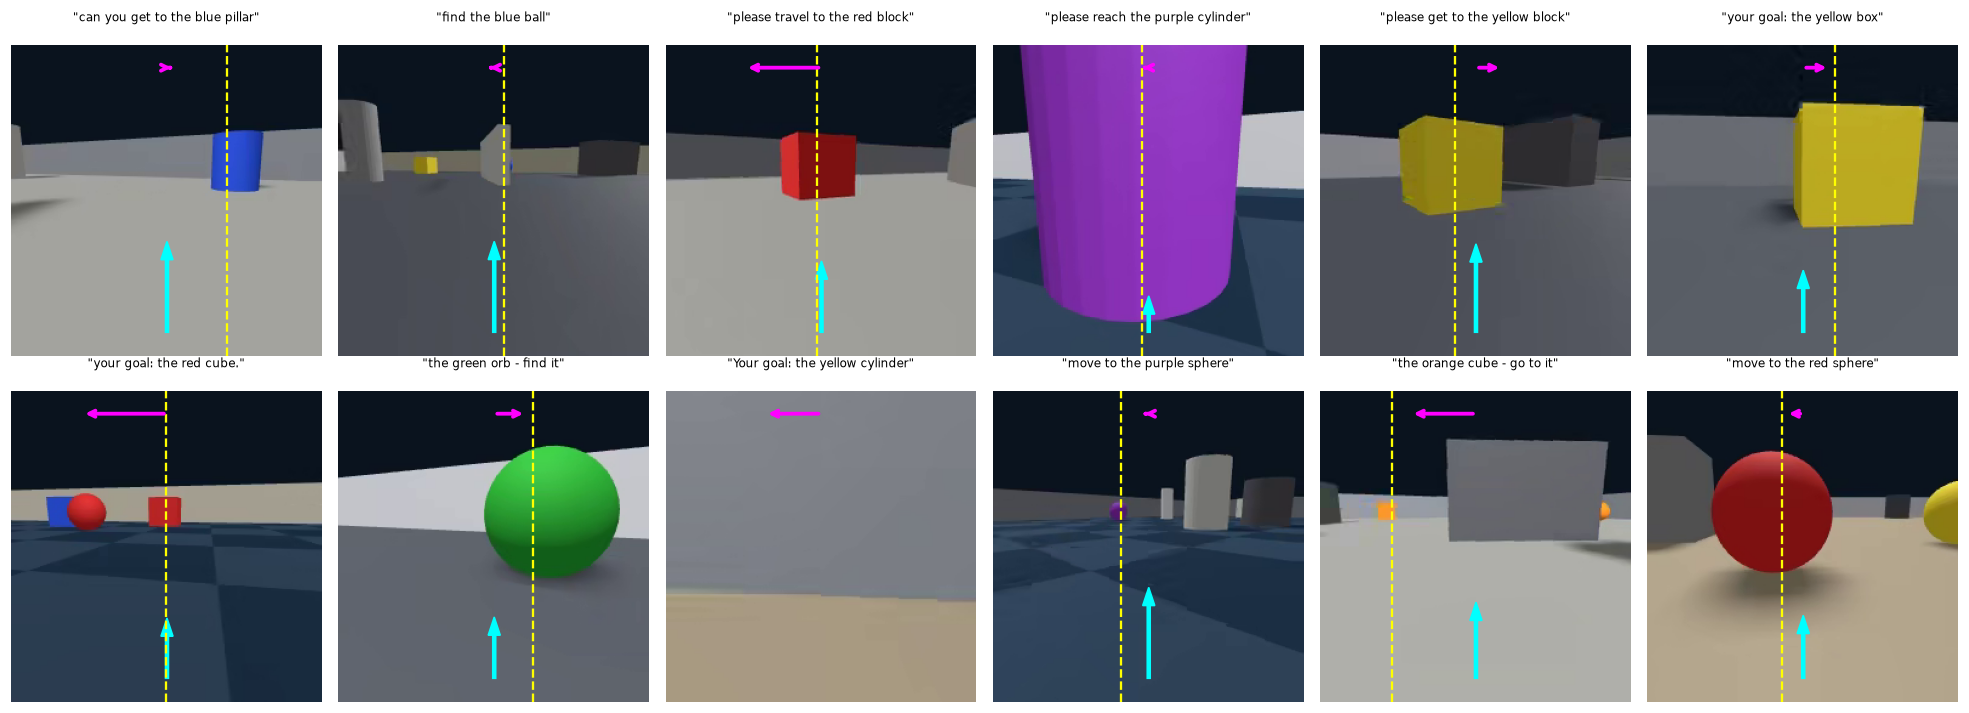

In [13]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6.6))
for ax, k in zip(axes.flat, range(12)):
    s = {key: (val[k] if key != "task" else val[k]) for key, val in batch.items()}
    show_sample(ax, s, f'"{s["task"]}"' + ("\n(mirrored)" if s["mirrored"] else "\n"))
plt.tight_layout(); plt.show()

## 10. The saved preparation file

Notebooks 04 and 05 shouldn't repeat these choices by hand. `make_scripted_prep` already wrote them to
`runs/datasets/scripted_close_prep.json` in section 3: where the recordings and the frame cache are, the split, the
chunk length and the action scaling. `carsim.data.load_training_data(...)` reads it back. (Mirroring is chosen in
the training settings of notebook 04, `BCConfig.mirror_p = 0.0`.) Here is what's inside:

In [14]:
print(f"{PREP}\n")
for k, v in prep.items():
    if k == "split":
        print(f"  {k:16s}", {kk: (f"{len(vv)} drives" if kk in ("train", "val", "excluded") else vv) for kk, vv in v.items()})
    elif k == "datasets":
        print(f"  {k:16s}", [d["name"] for d in v])
    else:
        print(f"  {k:16s}", v)

/home/mayur/Projects/obstacle_avoidance/runs/datasets/scripted_close_prep.json

  chunk            10
  mirror_p         0.0
  paraphrase       True
  action_limits    [0.800000011920929, 0.6000000238418579, 1.5]
  datasets         ['expert_sgc_rooms_1', 'expert_sgc_rooms_2', 'expert_sgc_rooms_3', 'expert_sgc_words_1', 'expert_sgc_words_2', 'expert_sgc_words_3']
  frame_cache      /home/mayur/Projects/obstacle_avoidance/runs/cache/scripted_close_prep_frames.npy
  split            {'train': '265 drives', 'val': '27 drives', 'excluded': '4 drives'}
  n_train_frames   17210
  n_val_frames     1659


## 11. Summary and next step

**What we built** (`carsim/data.py`)
- ✅ One table and one frame cache for the six scripted recordings: the videos are decoded once, and random access
  becomes instant.
- ✅ A split by room layout (about 265 train / 27 validation drives), with "orange sphere" held out.
- ✅ 10-step action chunks with zero padding and a mask at episode ends.
- ✅ Range scaling of actions and speed to [-1, 1].
- ✅ Mirror augmentation, verified visually and numerically (and switched off for this data, with the reason), and
  prompt paraphrases with evaluation-only wordings kept aside.
- ✅ A fast multi-worker DataLoader and a saved preparation file.

**What you learned:** data leakage and why we split by layout; why policies predict action chunks; why the scale of
numbers matters for flow matching; how to make augmentations that keep labels correct, and when not to use one.

**Next: notebook 04, imitation training.** smolVLA learns to drive from these samples, once with its own
arm-pretrained action head and once with a new car-specific one, with live graphs and driving tests.